# GDAL

! je pred commandom, da deljuje v jupytru, drugače se ga ne piše v terminalu. % je podobno magic command.

Dokumentacija: https://gdal.org/en/stable/

In [2]:
!gdalinfo --version

GDAL 3.12.2 "Chicoutimi", released 2026/02/03


In [3]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools

C:\KODA\GDAL\gdal-tools\gdal-tools


In [4]:
!dir

 Volume in drive C is Windows
 Volume Serial Number is BE32-0328

 Directory of C:\KODA\GDAL\gdal-tools\gdal-tools

23. 02. 2026  11:34    <DIR>          .
23. 02. 2026  11:34    <DIR>          ..
23. 02. 2026  11:33             8.196 .DS_Store
23. 02. 2026  11:33         8.648.529 1870_southern-india.jpg
23. 02. 2026  11:33               451 batch.py
23. 02. 2026  11:33               608 batch_parallel.py
23. 02. 2026  11:34    <DIR>          earthquakes
23. 02. 2026  11:33         8.106.233 earth_at_night.jpg
23. 02. 2026  11:34    <DIR>          geonames
23. 02. 2026  11:34    <DIR>          landsat8
23. 02. 2026  11:34    <DIR>          london_1m_dsm
23. 02. 2026  11:34    <DIR>          naip
23. 02. 2026  11:33           217.088 precipitation.gpkg
23. 02. 2026  11:34    <DIR>          prism
23. 02. 2026  11:33           868.352 spatial_query.gpkg
24. 02. 2026  16:29    <DIR>          srtm
23. 02. 2026  11:33         1.667.065 worldcities.csv
               8 File(s)     19.516.522

## OSNOVNO PROCESIRANJE RASTROV

### MERG


`dir` da našteješ vse fajle; `/b` samo osnovni podatki

In [5]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools\srtm
!dir /b   

C:\KODA\GDAL\gdal-tools\gdal-tools\srtm
colormap.txt
hillshade.tif
hillshade_combined.tif
merge.tif
merge.vrt
N27E086.hgt
N27E087.hgt
N28E086.hgt
N28E087.hgt
seznam_fajlov.txt


Informacije o fajlu

`gdalinfo <INPUT>`

In [6]:
!gdalinfo N27E086.hgt 

Driver: SRTMHGT/SRTMHGT File Format
Files: N27E086.hgt
Size is 3601, 3601
Coordinate System is:
GEOGCRS["WGS 84",
    DATUM["World Geodetic System 1984",
        ELLIPSOID["WGS 84",6378137,298.257223563,
            LENGTHUNIT["metre",1]]],
    PRIMEM["Greenwich",0,
        ANGLEUNIT["degree",0.0174532925199433]],
    CS[ellipsoidal,2],
        AXIS["geodetic latitude (Lat)",north,
            ORDER[1],
            ANGLEUNIT["degree",0.0174532925199433]],
        AXIS["geodetic longitude (Lon)",east,
            ORDER[2],
            ANGLEUNIT["degree",0.0174532925199433]],
    ID["EPSG",4326]]
Data axis to CRS axis mapping: 2,1
Origin = (85.999861111111116,28.000138888888888)
Pixel Size = (0.000277777777778,-0.000277777777778)
Metadata:
  AREA_OR_POINT=Point
Corner Coordinates:
Upper Left  (  85.9998611,  28.0001389) ( 85d59'59.50"E, 28d 0' 0.50"N)
Lower Left  (  85.9998611,  26.9998611) ( 85d59'59.50"E, 26d59'59.50"N)
Upper Right (  87.0001389,  28.0001389) ( 87d 0' 0.50"E, 28d 0' 0.

#### Virtual raster

Najboljši način je, da se nardi list fajlov in pol se uporabi ta list kot input za build.

*se upporabi da dobiš vse fajle, ^ se uporablja za pisanje v novo vrstico

puščica > daj v ta fajl,  /b bare format brez opisov

In [7]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools\srtm
!dir *.hgt     
!dir /b *.hgt > seznam_fajlov.txt  
                                 

C:\KODA\GDAL\gdal-tools\gdal-tools\srtm
 Volume in drive C is Windows
 Volume Serial Number is BE32-0328

 Directory of C:\KODA\GDAL\gdal-tools\gdal-tools\srtm

23. 02. 2026  11:33        25.934.402 N27E086.hgt
23. 02. 2026  11:33        25.934.402 N27E087.hgt
23. 02. 2026  11:33        25.934.402 N28E086.hgt
23. 02. 2026  11:33        25.934.402 N28E087.hgt
               4 File(s)    103.737.608 bytes
               0 Dir(s)  312.980.471.808 bytes free


In [8]:
!gdalbuildvrt -input_file_list seznam_fajlov.txt merge.vrt

0...10...20...30...40...50...60...70...80...90...100 - done.


### Izračun višin

Gledaš maximum 

In [9]:
!gdalinfo C:\KODA\GDAL\gdal-tools\gdal-tools\srtm\merge.vrt -stats


Driver: VRT/Virtual Raster
Files: C:\KODA\GDAL\gdal-tools\gdal-tools\srtm\merge.vrt
       C:\KODA\GDAL\gdal-tools\gdal-tools\srtm\N27E086.hgt
       C:\KODA\GDAL\gdal-tools\gdal-tools\srtm\N27E087.hgt
       C:\KODA\GDAL\gdal-tools\gdal-tools\srtm\N28E086.hgt
       C:\KODA\GDAL\gdal-tools\gdal-tools\srtm\N28E087.hgt
Size is 7201, 7201
Coordinate System is:
GEOGCRS["WGS 84",
    DATUM["World Geodetic System 1984",
        ELLIPSOID["WGS 84",6378137,298.257223563,
            LENGTHUNIT["metre",1]]],
    PRIMEM["Greenwich",0,
        ANGLEUNIT["degree",0.0174532925199433]],
    CS[ellipsoidal,2],
        AXIS["geodetic latitude (Lat)",north,
            ORDER[1],
            ANGLEUNIT["degree",0.0174532925199433]],
        AXIS["geodetic longitude (Lon)",east,
            ORDER[2],
            ANGLEUNIT["degree",0.0174532925199433]],
    ID["EPSG",4326]]
Data axis to CRS axis mapping: 2,1
Origin = (85.999861111111116,29.000138888888888)
Pixel Size = (0.000277777777778,-0.00027777777777

### Converting formats

Gdal sam zazna iz končnice v kaj hočeš convertat. Lahko pa se doda še `-of <IME FORMATA>` za cilni format.

`gdal_translate -of <IME FORMATA> <INPUT> <OUTPUT>  `

In [10]:
!gdal_translate merge.vrt merge.tif  

Input file size is 7201, 7201
0...10...20...30...40...50...60...70...80...90...100 - done.


Vsi formati

In [11]:
!gdal_translate --formats  

Supported Formats: (ro:read-only, rw:read-write, +:write from scratch, u:update, v:virtual-I/O s:subdatasets)
  DERIVED -raster- (ro): Derived datasets using VRT pixel functions
  GTI -raster- (rov): GDAL Raster Tile Index (*.gti.gpkg, *.gti.fgb, *.gti)
  SNAP_TIFF -raster- (rov): Sentinel Application Processing GeoTIFF
  GTiff -raster- (rw+uvs): GeoTIFF (*.tif, *.tiff)
  COG -raster- (wv): Cloud optimized GeoTIFF generator (*.tif, *.tiff)
  LIBERTIFF -raster- (rov): GeoTIFF (using LIBERTIFF library) (*.tif, *.tiff)
  VRT -raster,multidimensional raster- (rw+uv): Virtual Raster (*.vrt)
  NITF -raster- (rw+uvs): National Imagery Transmission Format (*.ntf)
  RPFTOC -raster- (rovs): Raster Product Format TOC format (*.toc)
  ECRGTOC -raster- (rovs): ECRG TOC format (*.xml)
  HFA -raster- (rw+uv): Erdas Imagine Images (.img) (*.img)
  SAR_CEOS -raster- (rov): CEOS SAR Image
  CEOS -raster- (rov): CEOS Image
  JAXAPALSAR -raster- (rov): JAXA PALSAR Product Reader (Level 1.1/1.5)
  GFF -ras

### Compressing

co - creation options, vedno compress, ker ni slabe strani compressiranja, razen počasnejšega procesiranja

In [12]:
!gdal_translate merge.vrt merge.tif -co COMPRESS=DEFLATE  


Input file size is 7201, 7201
0...10...20...30...40...50...60...70...80...90...100 - done.


tiled-da se deli rasterja shranjujejo v blocku, predictor je še dodatno compresiranje 100,101,102 ->100. 1, 2. Predictor 2 je za int, predictor 3 je pa za float.

`gdal_translate <INPUT> <OUTPUT> -co COMPRESS=DEFLATE -co TILED=YES -co PREDICTOR=2`

In [13]:
!gdal_translate merge.vrt merge.tif -co COMPRESS=DEFLATE -co TILED=YES -co PREDICTOR=2

Input file size is 7201, 7201
0...10...20...30...40...50...60...70...80...90...100 - done.


### No Data vrednosti

`-a_nodata -9999`

In [14]:
!gdal_translate merge.vrt merge.tif -co COMPRESS=DEFLATE -co TILED=YES -co PREDICTOR=2 -a_nodata -9999

Input file size is 7201, 7201
0...10...20...30...40...50...60...70...80...90...100 - done.


### Cloud Optimized GeoTIFF (COG)

COG omogoča hitro dostopanje rastrov preko interneta. Dostopaš samo do dela slike, ki ga potrebuješ, ne celotne slike na serverju. Ta format podpirajo vse programske opreme. 

Tutorial: https://www.youtube.com/watch?v=vHrT9pKmQgQ&list=PLppGmFLhQ1HLVaHVf4TsnJ4HXZBSfxLOK&index=12

`!gdal_translate -of COG <INPUT> <OUTPUT.TIF> -co COMPRESS=DEFLATE -co PREDICTOR=YES -co NUM_THREADS=ALL_CPUS -a_nodata -9999`

## PROCESSING ELEVATION DATA

### Hillshade

`gdaldem hillshade <INPUT.tif> <OUTPUT.tif> -s NUM`

Dokumentacija: https://gdal.org/en/stable/programs/gdal_raster_hillshade.html#gdal-raster-hillshade

Veliko več opcij.

Če sta X in Y v stopinjah Z pa v metrih, je potrebno določiti scale -s. V tem primeru 111120. Pri CRS-jih,ki so v metrih, kot npr. EPSG:3794, scale ni potreben. 

In [15]:
!gdaldem hillshade merge.tif hillshade.tif -s 111120

0...10...20...30...40...50...60...70...80...90...100 - done.


####  Multidirectional hillshade

`gdaldem hillshade <INPUT.tif> <OUTPUT.tif> -s NUM -multidirectional`

In [16]:
!gdaldem hillshade merge.tif hillshade_combined.tif -s 111120 -multidirectional

0...10...20...30...40...50...60...70...80...90...100 - done.


### Barvni relief

Različne višine, različne barve. Potreben je .txt fajl z definiranimi barvami (RGB). Lahko se ga naredi v QGisu.


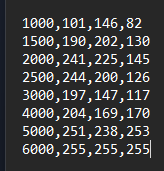

`gdaldem color-relief <INPUT> <COLORMAP.txt> <OUTPUT>`

In [ ]:
!gdaldem color-relief merge.tif colormap.txt colorized.tif

0...10...20...30...40...50...60...70...80...90...100 - done.


## Procesiranje aero-fotografij

In [8]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools\naip
!dir /b

C:\KODA\GDAL\gdal-tools\gdal-tools\naip
aoi.cpg
aoi.dbf
aoi.prj
aoi.qpj
aoi.shp
aoi.shx
filelist.txt
index.dbf
index.prj
index.shp
index.shx
NAIP.vrt
naip_preview.jpg
naip_preview.jpg.aux.xml
output_1_1.jp2
output_1_2.jp2
output_1_3.jp2
output_1_4.jp2
output_1_5.jp2
output_1_6.jp2
output_1_7.jp2
output_1_8.jp2
output_2_1.jp2
output_2_2.jp2
output_2_3.jp2
output_2_4.jp2
output_2_5.jp2
output_2_6.jp2
output_2_7.jp2
output_2_8.jp2
output_3_1.jp2
output_3_2.jp2
output_3_3.jp2
output_3_4.jp2
output_3_5.jp2
output_3_6.jp2
output_3_7.jp2
output_3_8.jp2
output_4_1.jp2
output_4_2.jp2
output_4_3.jp2
output_4_4.jp2
output_4_5.jp2
output_4_6.jp2
output_4_7.jp2
output_4_8.jp2
output_5_1.jp2
output_5_2.jp2
output_5_3.jp2
output_5_4.jp2
output_5_5.jp2
output_5_6.jp2
output_5_7.jp2
output_5_8.jp2
output_6_1.jp2
output_6_2.jp2
output_6_3.jp2
output_6_4.jp2
output_6_5.jp2
output_6_6.jp2
output_6_7.jp2
output_6_8.jp2
output_7_1.jp2
output_7_2.jp2
output_7_3.jp2
output_7_4.jp2
output_7_5.jp2
output_7_6.jp

Najprej naredimo virtual raster. Dodamo še `-addalpha` da so no data values nevidne (da jih v četrti transparentni band). 

In [2]:
!dir /b *.jp2 >filelist.txt 
!gdalbuildvrt -addalpha -input_file_list filelist.txt NAIP.vrt

File Not Found
ERROR 1: No input dataset specified.
Usage: gdalbuildvrt [--help] [--long-usage] [--help-general]
                    [--quiet]
                    [[-strict]|[-non_strict]]
                    [-tile_index <field_name>]
                    [-resolution user|average|common|highest|lowest|same]
                    [-tr <xres> <yes>] [-input_file_list <filename>]
                    [[-separate]|[-pixel-function <function>]]
                    [-pixel-function-arg <NAME>=<VALUE>]...
                    [-allow_projection_difference] [-sd <n>] [-tap]
                    [-te <xmin> <ymin> <xmax> <ymax>] [-addalpha] [-b <band>]...
                    [-hidenodata] [-overwrite]
                    [-srcnodata "<value>[ <value>]..."]
                    [-vrtnodata "<value>[ <value>]..."] [-a_srs <srs_def>]
                    [-r nearest|bilinear|cubic|cubicspline|lanczos|average|mode]
                    [-oo <NAME>=<VALUE>]... [-co <NAME>=<VALUE>]...
                    [-

Naredimo še preview. Z `-b 1 -b 2 -b 3` določimo katere bande hočemo da gdal uporabi. Z `-outsize 2% 2%` pa velikost. V tem primeru 2% originala (prvi procent širina, drugi pa širina).

`!gdal_translate <BANDI> -of <IME FORMATA> -outsize <VELIKOST> <INPUT> <OUTPUT>`

In [2]:
!gdal_translate -b 1 -b 2 -b 3 -of JPEG -outsize 2% 2% naip.vrt naip_preview.jpg 

ERROR 4: naip.vrt: No such file or directory


### Mreža input tailov

`--optfile` da se lahko doda txt file z več komandami.

`-write_absolute_path` da v tail zapiše absolute path ne samo relative.

`gdaltindex -write_absolute_path <OUTPUT.shp> --optfile <FILELIST.txt>`

In [3]:
!gdaltindex -write_absolute_path index.shp --optfile filelist.txt

ERROR 1: file_or_dir: 1 or more argument(s) expected. 0 provided.
Usage: gdaltindex [--help] [--long-usage] [--help-general]
                  [-overwrite] [-recursive] [-filename_filter <val>]...
                  [-min_pixel_size <val>] [-max_pixel_size <val>]
                  [-of <output_format>] [-tileindex <field_name>]
                  [-write_absolute_path] [-skip_different_projection]
                  [-t_srs <srs_def>] [-src_srs_name <field_name>]
                  [-src_srs_format {AUTO|WKT|EPSG|PROJ}] [-lyr_name <name>]
                  [-lco <NAME>=<VALUE>]... [-gti_filename <filename>]
                  [-tr <xres> <yres>] [-te <xmin> <ymin> <xmax> <ymax>]
                  [-ot <datatype>] [-bandcount <val>] [-nodata <val>]...
                  [-colorinterp <val>]... [-mask] [-mo <name>=<value>]...
                  [-fetch_md <gdal_md_name> <fld_name> <fld_type>]... [--quiet]
                  <index_file> <file_or_dir>...


### Mozaik in izrez na AOI

`gdalwarp -cutline <VECTOR INPUT>  -crop_to_cutline <INPUT RASTER> <OUTPUT> -co COMPRESS=DEFLATE -co TILED=YES`

In [9]:

!gdalwarp -cutline aoi.shp  -crop_to_cutline NAIP.vrt aoi_cut.tif -co COMPRESS=DEFLATE -co TILED=YES

Using band 4 of source image as alpha.
Creating output file that is 20034P x 26214L.
Processing NAIP.vrt [1/1] : 0...10...20...30...40...50...60...70...80...90...100 - done in 00:01:40.


Ker je rezultat ogromen, ga rabimo kompresirat. Zaradi artefaktov na strani dodamo `--config GDAL_TIFF_INTERNAL_MASK YES`, saj to ustvari interno masko na podlagi alfa kanala.

`gdal_translate <INPUT RASTER> <OUTPUT RASTER> -co COMPRESS=JPEG -co TILED=YES -co PHOTOMETRIC=YCBCR -co JPEG_QUALITY=75 -b 1 -b 2 -b 3 -mask 4 --config GDAL_TIFF_INTERNAL_MASK YES`

In [10]:
!gdal_translate aoi_cut.tif aoi.tif -co COMPRESS=JPEG -co TILED=YES -co PHOTOMETRIC=YCBCR -co JPEG_QUALITY=75 -b 1 -b 2 -b 3 -mask 4 --config GDAL_TIFF_INTERNAL_MASK YES

Input file size is 20034, 26214
0...10...20...30...40...50...60...70...80...90...100 - done in 00:00:08.


Rezultat je 20x manjši fajl.

### Overview  oz. piramide

Ko hočemo si ogledati velik fajl v npr. QGisu QGis ponavadi zmrne. Zato v fajl dodamo overviewje. To pomeni slike v zelo majhni resoluciji, in ko zoomeramo na določen del slike se naloži bolj detaljna slika. 

`gdaladdo -r bilinear --config COMPRESS_OVERVIEW JPEG <INPUT RASTER>`

In [11]:
!gdaladdo -r bilinear --config COMPRESS_OVERVIEW JPEG aoi.tif

0...10...20...30...40...50...60...70...80...90...100 - done in 00:00:32.


## Procesiranje satelitskih posnetkov

Satelitski posnetki so v veliko več kakor kakor normelne fotografije. 1,2,3 za RGB, 5 infrardeča, 8 pankromatski... 

In [1]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools\landsat8
!dir /b

C:\KODA\GDAL\gdal-tools\gdal-tools\landsat8
rgb.tif
rgb.tif.aux.xml
rgb.vrt
rgb_stretch.tif
rgb_stretch.tif.aux.xml
RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B2.tif
RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B3.tif
RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B4.tif
RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B5.tif
RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B8.tif


Najprej naredimo vrt za vse tri RGB kanale: 

`gdalbuildvrt -o <OUTPUT> -separate <INPUT> <INPUT> <INPUT>`

`-separate` dodamo, da gdal ve da so vsi na istem mestu in ne naredi mozaika. Pmembno je tudi zaporedje inputa. To lahko uporabimo tudi, če imamo fotografijo istega prostora v različnih letnih časih.

In jih nato združimo:

`gdal_translate <INPUT> <OUTPUT> -co PHOTOMETRIC=RGB -co COMPRESS=DEFLATE `

`PHOTOMETRIC=RGB` da se iterpretira rezultat kot rgb sliko


In [5]:
!gdalbuildvrt -o rgb.vrt -separate RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B4.tif RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B3.tif RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B2.tif

0...10...20...30...40...50...60...70...80...90...100 - done.


In [6]:
!gdal_translate rgb.vrt rgb.tif -co PHOTOMETRIC=RGB -co COMPRESS=DEFLATE 

Input file size is 7701, 7861
0...10...20...30...40...50...60...70...80...90...100 - done in 00:00:10.


### Razteg histograma

Ker imajo rgb vrednosti tudi znanstveni pomen, se jih ponavadi ne sme stiskati.

Vsatviti rabimo stare inj nove vrednosti. `-ot Byte` da shranimo kot bajt. 

`gdal_translate -scale <ORG MIN> <ORG MAX> <NOV MIN> <NOV MAX> -ot Byte <INPUT> <OUTPUT>`

In [7]:
!gdal_translate -scale 0 0.3 0 255 -ot Byte rgb.tif rgb_stretch.tif

Input file size is 7701, 7861
0...10...20...30...40...50...60...70...80...90...100 - done.


Ta postopek je samo za vizualizacije, saj smo izgubili sprektralne vrednosti za znanstveno analizo.

Če imamo veiko temnih delov lahko dodamo `-exponent <NUM>` z vrednostjo med 0 in 2 (priporočljivo 0,5 da so temni piksli svetlejši in 1,5 da so svetli piksli temnejši). To nared nelinearen razteg.

In [8]:
!gdal_translate -scale 0 0.3 0 255 -exponent 0.5 -ot Byte rgb.tif rgb_stretch.tif

Input file size is 7701, 7861
0...10...20...30...40...50...60...70...80...90...100 - done in 00:00:06.


## Rasterska algebra

Zraven gdala je vključen skript za rasterski kalkulator `gdal_calc.py`.
Za računanje spektralnih indicev, reklasifikacijo, delanje pikselnih kompozitov...

Input se poimenuje s črkami -A input 1, B input 2... Output pa `--outfile`

`--calc` da se specificira operacija.

Creation options `--co`

### Primer reklasifikacije

Hočemo da so piksli z vrednostjo <=5000 --> 0  in >5000 -->1

`gdal_calc.py - A <INPUT> --calc="A>5000" --outfile <OUTPUT> --co COMPRESS=DEFLATE --co TILED=YES --co PREDICATOR=2`

`A>5000` pomeni da bo vsem pikslom z vrednostjo večjo od 5000 dal novo vrednost 1. Ostale vrednosti postanejo 0.

In [2]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools\srtm
!gdal_calc.py - A merge.tif --calc="A>5000" --outfile binary.tif --co COMPRESS=DEFLATE --co TILED=YES --co PREDICATOR=2

C:\KODA\GDAL\gdal-tools\gdal-tools\srtm


<!-- ### Primer reklasifikacije (Multiclass) -->

Tu bodo namesto 2 razredov 4.

- <=1000 -->10
- > 1000 in <=5000 --> 50
- > 5000 in <=8000 --> 75
- > 8000 --> 100

`gdal_calc.py - A <INPUT> --calc="10*(A<=1000) + 50*(logical _and(A>1000, A<5000)) + 75*(logical_and(A>5000, A<8000)) + 100*(A>8000) " --outfile <OUTPUT> --co COMPRESS=DEFLATE --co TILED=YES --co PREDICATOR=2`

Z `+` dodajamo operacije. `logical_and` uporabimo za združevanje pogojev. 

`A <1000` pogleda če je piksel vrednost večja ali manjša (True=1 ali False=0) in nato to vrednost (1 ali 0) množimo `*` z željeno vrednostjo.



In [3]:
!gdal_calc.py - A merge.tif --calc="10*(A<=1000) + 50*(logical _and(A>1000, A<5000)) + 75*(logical_and(A>5000, A<8000)) + 100*(A>8000) " --outfile multiclass.tif --co COMPRESS=DEFLATE --co TILED=YES --co PREDICATOR=2

Z gdal kalkultorjem lahko delamo npr. tudi barvne hillshade. 

## Spektralni indijci in kanalna razmerja

Različna površja odbijajo različno valovno dolžino svetlobe

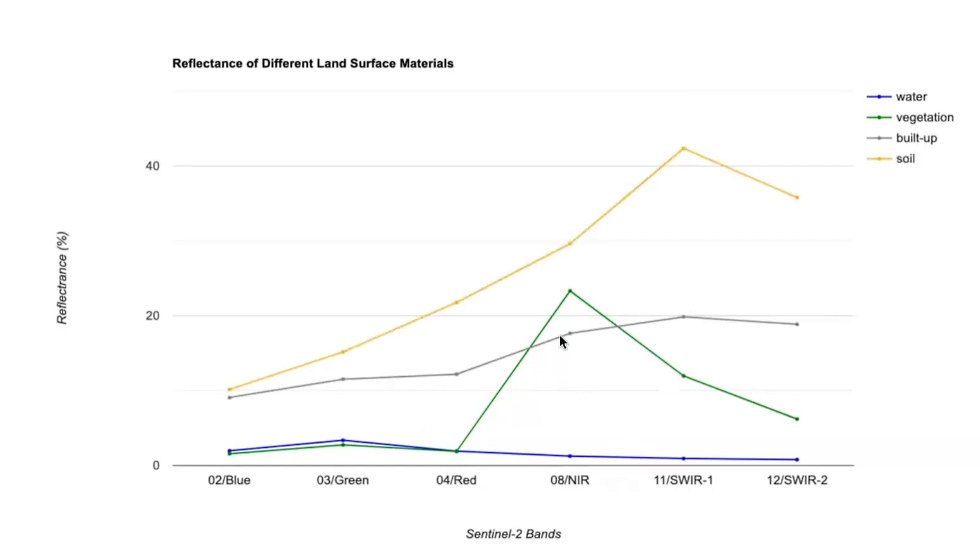

Zato jih lahko mešamo in ločujemo, da dobimo čim boljše rezultate za iterpretacijo.



In [9]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools\landsat8

C:\KODA\GDAL\gdal-tools\gdal-tools\landsat8


### NDVI (Normalized Difference Vegetation Index)

Z NDVI lahko izračunamo kako zdrava je vegetacija, saj vegetacija absorbira rdečo svetlobo in odbija infrardečo.

Izračuna se ga  `NDVI=NIR-Red/NIR+Red`

Delimo da dobimo ezultat med 0 in 1. Višji ko je rezultat bolj zdrava je vegetacija. Vbistvu računamo razmerje med odbojem rdeče in infra rdeče. 



`gdal_calc.py -A <INPUT NIR> -B <INPUT RED> --outfile <OUTPUT> --calc="(A-B)/(A+B)" --NoDataValue=-999`

In [ ]:
!python %CONDA_PREFIX%\Scripts\gdal_calc.py -A RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B5.tif -B RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B4.tif --outfile ndvi.tif --calc="(A-B)/(A+B)" --NoDataValue=-999

` %CONDA_PREFIX%\Scripts\gdal_calc.py` lokacija skripta.

## Pan sharpening

Se uporablja za izboljšanje resolucije s tem, da se združita visoko-ločljivi pankromatki kanal in nižje ločljivi RGB kanal. Za to se uporabi algoritem Brovey.

Se pa tega ne sme delati za znanstveno analizo, saj se izgubijo vrednosti pikslov.

`gdal_pansharpen.py <PANKROMATSKI INPUT> <RGB INPUT ZA IZBOLJŠAVO> <OUTPUT> -r bilinear -co COMPRESS=DEFLATE -co PHOTOMETRIC=RGB`

Nato pa še popravimo kontrast:

`gdal_translate -scale 0 0.3 0 255 -exponent 0.5 -ot Byte -a_nodata 0 <INPUT> <OUTPUT>`

In [15]:
!python %CONDA_PREFIX%\Scripts\gdal_pansharpen.py RT_LC08_L1TP_137042_20190920_20190926_01_T1_2019-09-20_B8.tif rgb.tif pansharpened.tif -r bilinear -co COMPRESS=DEFLATE -co PHOTOMETRIC=RGB

0...10...20...30...40...50...60...70...80...90...100 - done in 00:00:47.


In [14]:
!gdal_translate -scale 0 0.3 0 255 -exponent 0.5 -ot Byte -a_nodata 0 pansharpened.tif pansharpened_stretch.tif

Input file size is 15401, 15721
0...10...20...30...40...50...60...70...80...90...100 - done.


0...10...20...30...40...50...60...70...80...90...100 - done in 00:00:45.


## WMS Plasti (Web Map Services)

Način kako dostopati do podatkov, ne da bi jih prenesli. Se posodablja avtomatko z novimi podatki. 

In [16]:
!gdalinfo "WMS:https://sedac.ciesin.columbia.edu/geoserver/ows?version=1.3.0"

ERROR 1: Failed to connect to sedac.ciesin.columbia.edu port 443 after 21188 ms: Could not connect to server
ERROR 1: Error returned by server : Failed to connect to sedac.ciesin.columbia.edu port 443 after 21188 ms: Could not connect to server (28)
gdalinfo failed - unable to open 'WMS:https://sedac.ciesin.columbia.edu/geoserver/ows?version=1.3.0'.


### Downloading WMS

Njaprej je potrebno narediti  xml fajl

`gdal_translate -of WMS <INPUT URL> <OUTPUT.xml>`

Nato ga lahko prenesemo.

`gdalwarp -tr <NUM X> <NUM Y> <INPUT.xml> <OUTPUT.tif> -co COMPRESS=DEFLATE -co TILED=YES`

`-tr` : target resolution v stopinjah.

`-te` : to dodamo, če želimo specifične koordinate (4).

Vbistvu je to AGis.



## Georeferenciranje

In [1]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools

C:\KODA\GDAL\gdal-tools\gdal-tools


Če poznamo koordinate kotov slike je georeferenciranje z gdalom enostavno.

`gdal_translate -a_ullr <ulx> <uly> <lrx> <lry> -a_srs <CRS> <INPUT> <OUTPUT> -co COMPRESS=JPEG -co TILED=YES -co PHOTOMETRIC=RGB`

`<ulx> <uly> <lrx> <lry>` xy koordinate dveh kotov (zgoraj-levo in spodaj-desno), saj potrebujemo samo dve točki kotov za georeferenciiranje.


In [3]:
!gdal_translate -a_ullr -180 90 180 -90 -a_srs EPSG:4326 earth_at_night.jpg earth_at_night.tif -co COMPRESS=JPEG -co TILED=YES -co PHOTOMETRIC=RGB

Input file size is 13500, 6750
0...10...20...30...40...50...60...70...80...90...100 - done.


### Georeferenciiranje z GCP

Ta postopek uporabimo, ko ne vemo koordinat točno kot npr. v prejšnjem primeru. Točke za georeferenciiranje lahko dobimo npr. v QGisu. Najlažje pa v Gimpu. Potrebujemo pixel(column), line (row), X, Y.

Najprej vpišemo koordinate na določene piksle.

`gdal_translate -gcp <pixel (column)> <line (row)> <X> <Y>  -gcp <PONOVNO TOČKE> -gcp <PONOVNO TOČKE> -gcp <PONOVNO TOČKE> -gcp <PONOVNO TOČKE> <INPUT> <OUTPUT>`

Nato pa georeferenciiramo z `gdalwarp`

Izbrati rabimo tip transformacije:
* Polynominal 1,2 ali 3: `-order <NUM>`
* Thin Plate Spline: `-tps` 





| Map type              | Distortion | GCPs | Recommended              |
| --------------------- | ---------- | ---- | ------------------------ |
| Modern scanned map    | Low        | Few  | Polynomial 1st–2nd order |
| Historical/warped map | High       | Many | Thin Plate Spline        |
| High accuracy needed  | Medium     | Many | TPS if careful           |


`gdalwarp -t_srs <CRS> <TIP TRANSFORMACIJE> -tr <RESOLUCIJA X Y>  <INPUT> <OUTPUT> -co COMPRESS=JPEG -co JPEG_QUALITY=50 -co PHOTOMETRIC=YCBCR`



In [3]:
!gdal_translate -gcp 418 893 70 15 -gcp 380 2432 70 5 -gcp 3453 2434  90 5 -gcp 3407 895 90 15 -gcp 2662 911 85 15 1870_southern-india.jpg india-with-gcp.tif

Input file size is 3957, 3071
0...10...20...30...40...50...60...70...80...90...100 - done.


In [4]:
!gdalwarp -t_srs EPSG:4042 -order 1 -tr 0.005 0.005  india-with-gcp.tif india-reprojected-polynomial.tif -co COMPRESS=JPEG -co JPEG_QUALITY=50 -co PHOTOMETRIC=YCBCR

Creating output file that is 5382P x 4035L.
Processing india-with-gcp.tif [1/1] : 0...10...20...30...40...50...60...70...80...90...100 - done.


In [7]:
!gdalinfo C:\KODA\GDAL\gdal-tools\gdal-tools\earth_at_night.tif

Driver: GTiff/GeoTIFF
Files: C:\KODA\GDAL\gdal-tools\gdal-tools\earth_at_night.tif
Size is 13500, 6750
Coordinate System is:
GEOGCRS["WGS 84",
    ENSEMBLE["World Geodetic System 1984 ensemble",
        MEMBER["World Geodetic System 1984 (Transit)"],
        MEMBER["World Geodetic System 1984 (G730)"],
        MEMBER["World Geodetic System 1984 (G873)"],
        MEMBER["World Geodetic System 1984 (G1150)"],
        MEMBER["World Geodetic System 1984 (G1674)"],
        MEMBER["World Geodetic System 1984 (G1762)"],
        MEMBER["World Geodetic System 1984 (G2139)"],
        MEMBER["World Geodetic System 1984 (G2296)"],
        ELLIPSOID["WGS 84",6378137,298.257223563,
            LENGTHUNIT["metre",1]],
        ENSEMBLEACCURACY[2.0]],
    PRIMEM["Greenwich",0,
        ANGLEUNIT["degree",0.0174532925199433]],
    CS[ellipsoidal,2],
        AXIS["geodetic latitude (Lat)",north,
            ORDER[1],
            ANGLEUNIT["degree",0.0174532925199433]],
        AXIS["geodetic longitude (Lo

## OGR (Vektorji)

Programi in skripti:

* `ogrinfo`: informacije

* `ogr2ogr`: konvertanje in transformiranje
* `ogrmerge.py`: združevanje vektorjev
* `ogr_layer_algebra.py`: operacije za geoprocesiranje(clip, intersekcija, unija)
* `ogrlineref`:
* `ogrtindex`: bounding box fajla


### Osnove ETL (Extract-Transform-Load)

In [4]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools
!dir /b

C:\KODA\GDAL\gdal-tools\gdal-tools
.DS_Store
1870_southern-india.jpg
batch.py
batch_parallel.py
earthquakes
earth_at_night.jpg
earth_at_night.tif
geonames
india-reprojected-polynomial.tif
india-with-gcp.tif
landsat8
london_1m_dsm
naip
precipitation.gpkg
prism
spatial_query.gpkg
srtm
worldcities.csv


`ogrinfo`: Za informacije o npr. CSV datoteki

Dokumentacija: https://gdal.org/en/stable/programs/ogrinfo.html

`-al`: list all layers

`-so`: summary only

In [6]:
!ogrinfo -al -so worldcities.csv

INFO: Open of `worldcities.csv'
      using driver `CSV' successful.

Layer name: worldcities
Geometry: None
Feature Count: 15493
Layer SRS WKT:
(unknown)
city: String (0.0)
city_ascii: String (0.0)
lat: String (0.0)
lng: String (0.0)
country: String (0.0)
iso2: String (0.0)
iso3: String (0.0)
admin_name: String (0.0)
capital: String (0.0)
population: String (0.0)
id: String (0.0)


Lahko vidimo, da csv vsebuje lat in lng, ampak pod geometry piše none. Zato moramo to convertat v x in y koordinate. To bomo naredili z `-oo` - open options. Torej, da se prebere stolpce lat in lng kot x in y.

`-oo X_POSSIBLE_NAMES=lng -oo Y_POSSIBLE_NAMES=lat`

In [7]:
!ogrinfo -so -al worldcities.csv -oo X_POSSIBLE_NAMES=lng -oo Y_POSSIBLE_NAMES=lat

INFO: Open of `worldcities.csv'
      using driver `CSV' successful.

Layer name: worldcities
Geometry: Point
Feature Count: 15493
Extent: (-179.590000, -54.933300) - (179.383300, 82.483300)
Layer SRS WKT:
(unknown)
city: String (0.0)
city_ascii: String (0.0)
lat: Real (0.0)
lng: Real (0.0)
country: String (0.0)
iso2: String (0.0)
iso3: String (0.0)
admin_name: String (0.0)
capital: String (0.0)
population: String (0.0)
id: String (0.0)


Tu lahko vidimo, da zadaj pod geometry piše point.

Naslednji korak je da konvertiramo v vektorso datoteko z `ogr2ogr`. Za to bomo uporabili ogr2ogr.

Dokumentacija: https://gdal.org/en/stable/programs/ogr2ogr.html

`ogr2ogr -f <FORMAT> <OUTPUT> <INPUT.csv> -oo X_POSSIBLE_NAMES=lng -oo Y_POSSIBLE_NAMES=lat `

Za razliko od gdala, kjer je input pred outputom, je pri ogr treba najprejh specifcirati output pred inputom.

Formata sicer ni potrebno specificirati, saj ga ogr ugotovi iz končnice.

Potrebno je specificirati še  CRS. To bomo naredili z `-a_srs`

In [11]:
!ogr2ogr -f GPKG worldcities.gpkg worldcities.csv -oo X_POSSIBLE_NAMES=lng -oo Y_POSSIBLE_NAMES=lat -a_srs EPSG:4326

### Filtriranje in subset

Želimo imeti samo mesta iz Slovenije. Ogr razume SQL, zato bomo uporabili te comande. Z `-where` bomo naredili atributno pizvedbo.

`-where "country = 'Slovenia'`



In [16]:
!ogr2ogr -f GPKG mycities.gpkg worldcities.csv -oo X_POSSIBLE_NAMES=lng -oo Y_POSSIBLE_NAMES=lat -a_srs EPSG:4326 -where "country = 'Slovenia'"

In [20]:
!ogrinfo -so -al mycities.gpkg

INFO: Open of `mycities.gpkg'
      using driver `GPKG' successful.

Layer name: worldcities
Geometry: Point
Feature Count: 212
Extent: (13.526400, 45.508400) - (16.450600, 46.836900)
Layer SRS WKT:
GEOGCRS["WGS 84",
    ENSEMBLE["World Geodetic System 1984 ensemble",
        MEMBER["World Geodetic System 1984 (Transit)"],
        MEMBER["World Geodetic System 1984 (G730)"],
        MEMBER["World Geodetic System 1984 (G873)"],
        MEMBER["World Geodetic System 1984 (G1150)"],
        MEMBER["World Geodetic System 1984 (G1674)"],
        MEMBER["World Geodetic System 1984 (G1762)"],
        MEMBER["World Geodetic System 1984 (G2139)"],
        MEMBER["World Geodetic System 1984 (G2296)"],
        ELLIPSOID["WGS 84",6378137,298.257223563,
            LENGTHUNIT["metre",1]],
        ENSEMBLEACCURACY[2.0]],
    PRIMEM["Greenwich",0,
        ANGLEUNIT["degree",0.0174532925199433]],
    CS[ellipsoidal,2],
        AXIS["geodetic latitude (Lat)",north,
            ORDER[1],
            ANG

Populacija je v dani datoteki string, ne pa int oz. float, kar ozežuje kaklkulacije zato jo rabimo konvertirat. Zato uporabimo `-sql`, da lahko uporabimo sql statement.

`ogr2ogr -f GPKG mycities.gpkg worldcities.csv -oo X_POSSIBLE_NAMES=lng -oo Y_POSSIBLE_NAMES=lat -a_srs EPSG:4326 -sql "SELECT city, country, CAST(population AS integer) as population from worldcities where country = 'Slovenia'"`

V tem primeru smo izbrali samo tri stolpce in sicer city, country in konvertiran population. 

`CAST(population AS integer) as population` pomeni naredi originalni population kot int v stolpcu population

In [22]:
!ogr2ogr -f GPKG mycities.gpkg worldcities.csv -oo X_POSSIBLE_NAMES=lng -oo Y_POSSIBLE_NAMES=lat -a_srs EPSG:4326 -sql "SELECT city, country, CAST(population AS integer) as population from worldcities where country = 'Slovenia'"

In [23]:
!ogrinfo -so -al mycities.gpkg

INFO: Open of `mycities.gpkg'
      using driver `GPKG' successful.

Layer name: worldcities
Geometry: Point
Feature Count: 212
Extent: (13.526400, 45.508400) - (16.450600, 46.836900)
Layer SRS WKT:
GEOGCRS["WGS 84",
    ENSEMBLE["World Geodetic System 1984 ensemble",
        MEMBER["World Geodetic System 1984 (Transit)"],
        MEMBER["World Geodetic System 1984 (G730)"],
        MEMBER["World Geodetic System 1984 (G873)"],
        MEMBER["World Geodetic System 1984 (G1150)"],
        MEMBER["World Geodetic System 1984 (G1674)"],
        MEMBER["World Geodetic System 1984 (G1762)"],
        MEMBER["World Geodetic System 1984 (G2139)"],
        MEMBER["World Geodetic System 1984 (G2296)"],
        ELLIPSOID["WGS 84",6378137,298.257223563,
            LENGTHUNIT["metre",1]],
        ENSEMBLEACCURACY[2.0]],
    PRIMEM["Greenwich",0,
        ANGLEUNIT["degree",0.0174532925199433]],
    CS[ellipsoidal,2],
        AXIS["geodetic latitude (Lat)",north,
            ORDER[1],
            ANG

Geopackage datoteke imajo lahko več plasti. Če hočemo spremeniti ime plasti bomo to naredili z `-nln`.

In [24]:
!ogr2ogr -f GPKG mycities.gpkg worldcities.csv -oo X_POSSIBLE_NAMES=lng -oo Y_POSSIBLE_NAMES=lat -a_srs EPSG:4326 -sql "SELECT city, country, CAST(population AS integer) as population from worldcities where country = 'Slovenia'" -nln mycities


### Združevanje vektorskih datotek

In [25]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools\earthquakes
!dir /b

C:\KODA\GDAL\gdal-tools\gdal-tools\earthquakes
2020_01.geojson
2020_02.geojson
2020_03.geojson
2020_04.geojson
2020_05.geojson
2020_06.geojson
2020_07.geojson
2020_08.geojson
2020_09.geojson
2020_10.geojson
2020_11.geojson
2020_12.geojson


Za združevanje uporabimo `ogrmerege.py` skript.

Za input se lahko uporabi list fajlov, lahko pa tudi wildcard `*`.

`python <LOKACIJA ogrmerge.py> -o <OUTPUT> <INPUT>`

Gpkg da vsak fajl v svojo plast, lahko pa se jih tudi združi vse v eno plast z `-single`.

Boljše pa je da to ptem damo v novo plast z `-nln` in prepišemo originalen dataset z `-overwrite_ds`

In [27]:
!python %CONDA_PREFIX%\Scripts\ogrmerge.py -o earthquakes.gpkg *.geojson -single -nln all_earthquakes -overwrite_ds

### Geoprocesiranje in prostorske poizvedbe

Imamo vektorsko datoteko z dvema plastema in želimo ugotoviti koliko točk prve plasti (pubs and bars) je v rangu 500m okoli točk druge plasti (metro station).

Najprej reprojektiramo iz stopinj v metre. In naredimo novo plast.

Če hočemo dostopati do določene plasti, jo napišemo za input datoteko. Npr. `spatial_query.gpkg bars_and_pubs`




In [ ]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools

!ogr2ogr -t_srs EPSG:7855 spatial_query.gpkg spatial_query.gpkg bars_and_pubs -update -nln bars_and_pubs_reprojected

!ogr2ogr -t_srs EPSG:7855 spatial_query.gpkg spatial_query.gpkg metro_stations -update -nln metro_stations_reprojected

C:\KODA\GDAL\gdal-tools\gdal-tools


Nato naredimo buffer okoli metro z`sql "SELECT m.station, ST_Buffer(m.geom, 500) as geom FROM  metro_stations_reprojected m" -dialect SQLITE ` Uporabili smo sql.

Dodamo še `SELECT ST_Union(d.geom) as geom FROM (SELECT ST_Collect(buffer(m.geom, 500))` da se bufferji, ki se prekrivajo združijo.

In [31]:
!ogr2ogr spatial_query.gpkg spatial_query.gpkg -update -nln metro_stations_buffer_dissolved -sql "SELECT ST_Union(d.geom) as geom FROM (SELECT ST_Collect(buffer(m.geom, 500)) as geom FROM metro_stations_reprojected m) as d" -dialect SQLITE

Nato izberemo vse postaje, ki padejo v buffer barov. To naredimo z `ogr_layer_algebra.py`. Z `Clip` clipamo postaje. Z `method_ds` in `method_lyr` določimo plast, ki jo clipamo.



In [32]:
!python %CONDA_PREFIX%\Scripts\ogr_layer_algebra.py Clip -input_ds spatial_query.gpkg -input_lyr bars_and_pubs_reprojected -method_ds spatial_query.gpkg -method_lyr metro_stations_buffer_dissolved -output_ds output.gpkg -output_lyr selected -nlt POINT

0...10...20...30...40...50...60...70...80...90...100 - done in 00:00:08.


Warning 6: Normalized/laundered field name: 'Census year' to 'Census yea'
Warning 6: Normalized/laundered field name: 'Property ID' to 'Property I'
Warning 6: Normalized/laundered field name: 'Base property ID' to 'Base prope'
Warning 6: Normalized/laundered field name: 'Street address' to 'Street add'
Warning 6: Normalized/laundered field name: 'CLUE small area' to 'CLUE small'
Warning 6: Normalized/laundered field name: 'Trading name' to 'Trading na'
Warning 6: Normalized/laundered field name: 'Number of patrons' to 'Number of'
Warning 6: Normalized/laundered field name: 'x coordinate' to 'x coordina'
Warning 6: Normalized/laundered field name: 'y coordinate' to 'y coordina'


## BATCH

In [33]:
%cd C:\KODA\GDAL\gdal-tools\gdal-tools


C:\KODA\GDAL\gdal-tools\gdal-tools


Batch skript, ki aplicira konverzacijo na vse datoteke v direktoriju.

In [ ]:
import os

input_dir = 'naip'

command_string = 'gdal_translate -of GTiff -co COMPRESS=JPEG {input} {output}'
for file in os.listdir(input_dir):
  if file.endswith('.jp2'):
    input = os.path.join(input_dir, file)
    filename = os.path.splitext(os.path.basename(file))[0] #split text ti loči ime od končnice, in pol z [0] zberemo ime iz lista
    output =  os.path.join(input_dir, filename + '.tif')
    command = command_string.format(input=input, output=output)
    print('Running ->', command)
    #print(f"Input: {input}")
    #print(f"Output:{output}")
    #os.system(command) # s tem se zaštarta komanda

Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_1_1.jp2 naip\output_1_1.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_1_2.jp2 naip\output_1_2.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_1_3.jp2 naip\output_1_3.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_1_4.jp2 naip\output_1_4.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_1_5.jp2 naip\output_1_5.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_1_6.jp2 naip\output_1_6.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_1_7.jp2 naip\output_1_7.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_1_8.jp2 naip\output_1_8.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_2_1.jp2 naip\output_2_1.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\output_2_2.jp2 naip\output_2_2.tif
Running -> gdal_translate -of GTiff -co COMPRESS=JPEG naip\o

Isti skript, samo da ta deluje z 4 jedri.

In [ ]:
import os
from multiprocessing import Pool

input_dir = 'naip'
command_string = 'gdal_translate -of GTiff -co COMPRESS=JPEG {input} {output}'

num_cores = 4

def process(file):
    input = os.path.join(input_dir, file)
    filename = os.path.splitext(os.path.basename(file))[0]
    output =  os.path.join(input_dir, filename + '.tif')
    command = command_string.format(input=input, output=output)
    print('Running ->', command)
    print(f"Input: {input}")
    print(f"Output:{output}")
    #os.system(command)
    
files = [file for file in os.listdir(input_dir) if file.endswith('.jp2')]

if __name__ == '__main__':
  p = Pool(num_cores)
  p.map(process, files)